# AirCast: next-day air quality forecast for Chicago

**Track:** Climate · **Team:** Parth Patel and Anay Goyal, Emerson High School

**Who is this for?** A school athletics director (or a parent) in Chicago deciding
*today* whether tomorrow's outdoor practice should be moved indoors. Fine-particle
pollution (PM2.5) is the pollutant that matters most for that call: it penetrates
deep into the lungs, and children exercising outdoors are among the most exposed.

**What it does:** predicts **tomorrow's PM2.5 as Chicago's EPA regulatory monitors
will measure it**, the number that drives official air-quality advisories, and
turns the prediction into a concrete two-level alert: *WATCH* (have an indoor
backup plan) and *WARNING* (move practice indoors).

**The rules we follow (from the brief):**
- One location (Chicago), one decision, one decider.
- Train on earlier dates, test on later dates, never shuffled.
- Every model is compared against the **persistence baseline**: "tomorrow will be
  the same as today." Beating it is the whole game in day-ahead forecasting.

## 1. The data, and why we checked it before trusting it

Three sources, all public, fetched by `src/fetch_data.py` and `src/fetch_epa.py`:

- **EPA regulatory monitors** (our prediction target): daily PM2.5 from all
  Cook County monitors with 24-hour samples, averaged into one city series.
  From the EPA Air Quality System annual files.
- **CAMS atmospheric model estimates** via [Open-Meteo](https://open-meteo.com/)
  (free, no key): hourly PM2.5 averaged to daily means, for Chicago and for four
  cities *upwind* on the Canadian-wildfire-smoke path (Minneapolis, Green Bay,
  Madison, Thunder Bay). These are *model* values, not measurements; the brief
  asks us to say this clearly, and it turned out to matter a lot (next cell).
- **Weather** (Open-Meteo historical archive): temperature, precipitation, wind,
  humidity, radiation, pressure.

Coverage: **2022-08-04 to 2025-11-12**, 1,197 days, no gaps in any series.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
# numpy's Accelerate BLAS on macOS raises spurious "divide by zero in matmul"
# RuntimeWarnings during Ridge regression. The outputs are correct - we assert
# every prediction is finite right after computing them (section 5).
warnings.filterwarnings("ignore", message=".*matmul.*", category=RuntimeWarning)

wx = pd.read_csv("data/daily.csv", parse_dates=["date"], index_col="date")
epa = pd.read_csv("data/epa_chicago.csv", parse_dates=["date"],
                  index_col="date")["epa_pm25"].loc["2022-08-04":"2025-11-12"]
up = pd.read_csv("data/upwind.csv", parse_dates=["date"], index_col="date")
cams = wx["pm25"]
WHO_DAILY = 15.0   # WHO 2021 daily guideline, ug/m3
EPA_DAILY = 35.0   # US EPA 24-hour standard, ug/m3

### We validated the convenient data against ground truth, then switched targets

Our first version trained *and evaluated* on the CAMS estimates alone, because
they're free and gapless. Before trusting that, we checked CAMS against the EPA
monitors:

Correlation (daily values): 0.67
Mean level: CAMS 11.7 vs EPA 9.2 µg/m³
Mean absolute disagreement: 4.2 µg/m³
Agreement on 'bad day' (>15 µg/m³): 83%
Worst day, June 27 2023: CAMS said 50, monitors measured 134


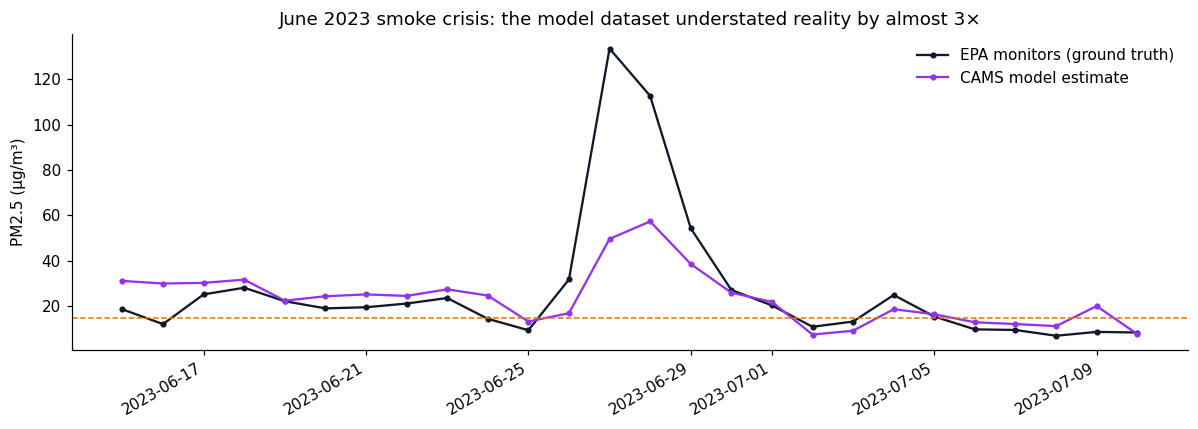

In [2]:
both = pd.concat([cams.rename("CAMS estimate"), epa.rename("EPA monitors")], axis=1).dropna()
print(f"Correlation (daily values): {both.corr().iloc[0, 1]:.2f}")
print(f"Mean level: CAMS {both['CAMS estimate'].mean():.1f} vs EPA {both['EPA monitors'].mean():.1f} µg/m³")
print(f"Mean absolute disagreement: {(both['CAMS estimate'] - both['EPA monitors']).abs().mean():.1f} µg/m³")
print(f"Agreement on 'bad day' (>15 µg/m³): {((both['CAMS estimate'] > 15) == (both['EPA monitors'] > 15)).mean():.0%}")
print(f"Worst day, June 27 2023: CAMS said {cams['2023-06-27']:.0f}, monitors measured {epa['2023-06-27']:.0f}")

fig, ax = plt.subplots(figsize=(11, 4))
window = slice("2023-06-15", "2023-07-10")
ax.plot(epa[window].index, epa[window], "o-", ms=3, color="#111827", label="EPA monitors (ground truth)")
ax.plot(cams[window].index, cams[window], "o-", ms=3, color="#9333ea", label="CAMS model estimate")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("June 2023 smoke crisis: the model dataset understated reality by almost 3×")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/01_cams_vs_epa.png", bbox_inches="tight")
plt.show()

Correlation of only ~0.67, and the worst day understated almost threefold. A
tool that forecasts *CAMS* could look accurate while misleading the person
acting on it. So AirCast **predicts the EPA monitor value**, what Chicago
actually breathes, and uses CAMS only as an input signal, where imperfect
information still helps.

### What three years of (real) Chicago air looks like

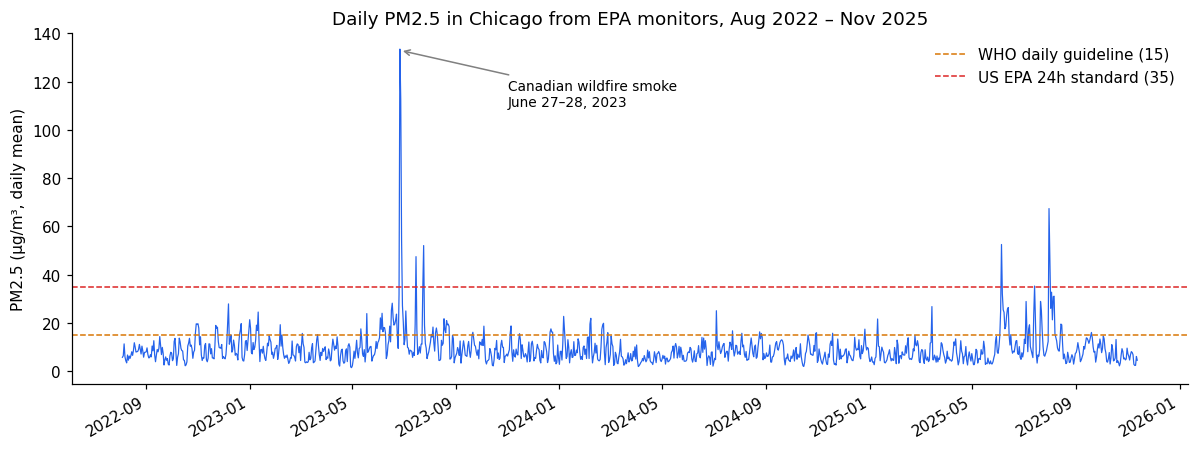

Days over WHO guideline (15): 126 of 1197 (11%)
Days over EPA standard (35):  9 of 1197


In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(epa.index, epa, lw=0.8, color="#2563eb")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1, label=f"WHO daily guideline ({WHO_DAILY:.0f})")
ax.axhline(EPA_DAILY, color="#dc2626", ls="--", lw=1, label=f"US EPA 24h standard ({EPA_DAILY:.0f})")
ax.annotate("Canadian wildfire smoke\nJune 27–28, 2023", xy=(pd.Timestamp("2023-06-27"), 133),
            xytext=(pd.Timestamp("2023-11-01"), 110), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_ylabel("PM2.5 (µg/m³, daily mean)")
ax.set_title("Daily PM2.5 in Chicago from EPA monitors, Aug 2022 – Nov 2025")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/02_history.png", bbox_inches="tight")
plt.show()

n = len(epa)
print(f"Days over WHO guideline (15): {(epa > WHO_DAILY).sum()} of {n} ({(epa > WHO_DAILY).mean():.0%})")
print(f"Days over EPA standard (35):  {(epa > EPA_DAILY).sum()} of {n}")

Roughly **1 day in 9** exceeds the WHO guideline, a real recurring decision,
not a once-a-year event. The extremes are wildfire smoke.

## 2. Features

To predict tomorrow, we only use information available **today**:

- the monitors' PM2.5 today, yesterday, the day before, and a 3-day average
  (in deployment this comes from EPA's live AirNow feed)
- today's weather: wind (disperses particles), rain (washes them out),
  temperature, humidity, radiation, pressure (stagnant days trap smog)
- the season, as sine/cosine of day-of-year so Dec 31 sits next to Jan 1

A second group, the **smoke signals**, joins in section 7, after we see why
it's needed. The target is **tomorrow's EPA daily-mean PM2.5**.

In [4]:
def build_features(epa_series, weather):
    f = pd.DataFrame(index=weather.index)
    f["epa_today"] = epa_series
    f["epa_lag1"] = epa_series.shift(1)
    f["epa_lag2"] = epa_series.shift(2)
    f["epa_3day_mean"] = epa_series.rolling(3).mean()
    for col in ["temperature_2m_mean", "temperature_2m_max", "precipitation_sum",
                "wind_speed_10m_max", "relative_humidity_2m_mean",
                "shortwave_radiation_sum", "surface_pressure_mean"]:
        f[col] = weather[col]
    # wind direction is circular (359 deg is next to 0 deg), so encode as sin/cos
    wd = np.deg2rad(weather["wind_direction_10m_dominant"])
    f["wind_dir_sin"], f["wind_dir_cos"] = np.sin(wd), np.cos(wd)
    doy = weather.index.dayofyear / 365.25 * 2 * np.pi
    f["season_sin"], f["season_cos"] = np.sin(doy), np.cos(doy)
    return f

features = build_features(epa, wx)
target = epa.shift(-1).rename("pm25_tomorrow")
data = features.join(target).dropna()
print(f"{data.shape[0]} usable days, {features.shape[1]} features")

1194 usable days, 15 features


## 3. Train/test split: by time, never shuffled

Tests use forecast issue dates in 2025 through November 11, the last date
with a known next-day reading. Training excludes any row whose target reading
falls on or after the test cutoff. The same rule applies to each forecast
horizon, the calibration period, and the 2023 replay.

In [5]:
SPLIT = "2025-01-01"


def before_cutoff(frame, cutoff, horizon=1):
    """Keep only rows whose target dates precede the cutoff."""
    return frame[frame.index + pd.Timedelta(days=horizon) < pd.Timestamp(cutoff)]


train, test = before_cutoff(data, SPLIT), data[data.index >= SPLIT]
X_train, y_train = train.drop(columns="pm25_tomorrow"), train["pm25_tomorrow"]
X_test, y_test = test.drop(columns="pm25_tomorrow"), test["pm25_tomorrow"]
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

Train: 878 days (2022-08-06 to 2024-12-30)
Test:  315 days (2025-01-01 to 2025-11-11)


## 4. Choosing a model without peeking at the test year

Candidates: **Ridge regression** (linear, regularized, on scaled features) and
**gradient-boosted trees** in a default and a conservative version. To choose
between them we use 5-fold time-series cross-validation inside the training
period, with a one-row gap so the final training target precedes validation.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def make_candidates():
    return {
        "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Gradient-boosted trees (default)": HistGradientBoostingRegressor(random_state=0),
        "Gradient-boosted trees (small)": HistGradientBoostingRegressor(
            max_leaf_nodes=7, learning_rate=0.05, max_iter=300, random_state=0),
    }

tscv = TimeSeriesSplit(n_splits=5, gap=1)
cv_mae = {}
for name, model in make_candidates().items():
    scores = cross_val_score(model, X_train, y_train, cv=tscv,
                             scoring="neg_mean_absolute_error")
    cv_mae[name] = -scores.mean()
persist_cv = np.mean([mean_absolute_error(y_train.iloc[va], X_train["epa_today"].iloc[va])
                      for _, va in tscv.split(X_train)])
cv_table = pd.Series({**cv_mae, "Persistence baseline": persist_cv},
                     name="CV MAE on training period (µg/m³)").sort_values().round(2)
cv_table

Ridge regression                    3.33
Persistence baseline                3.53
Gradient-boosted trees (small)      3.76
Gradient-boosted trees (default)    3.78
Name: CV MAE on training period (µg/m³), dtype: float64

## 5. Local model results on the 2025 test period

In [7]:
best_name = cv_table.drop("Persistence baseline").idxmin()
candidates = make_candidates()
preds = {"Persistence (tomorrow = today)": X_test["epa_today"]}
for name, model in candidates.items():
    model.fit(X_train, y_train)
    preds[name] = pd.Series(model.predict(X_test), index=X_test.index)
for name, p in preds.items():
    assert np.isfinite(p).all(), f"non-finite predictions from {name}"

results = pd.DataFrame({
    name: {"MAE (µg/m³)": mean_absolute_error(y_test, p),
           "RMSE (µg/m³)": root_mean_squared_error(y_test, p)}
    for name, p in preds.items()
}).T.round(2)
print(f"Model chosen by cross-validation: {best_name}")
results

Model chosen by cross-validation: Ridge regression


,MAE (µg/m³),RMSE (µg/m³)
Persistence (tomorrow = today),3.46,6.02
Ridge regression,3.23,5.53
Gradient-boosted trees (default),3.54,6.10
Gradient-boosted trees (small),3.42,6.08


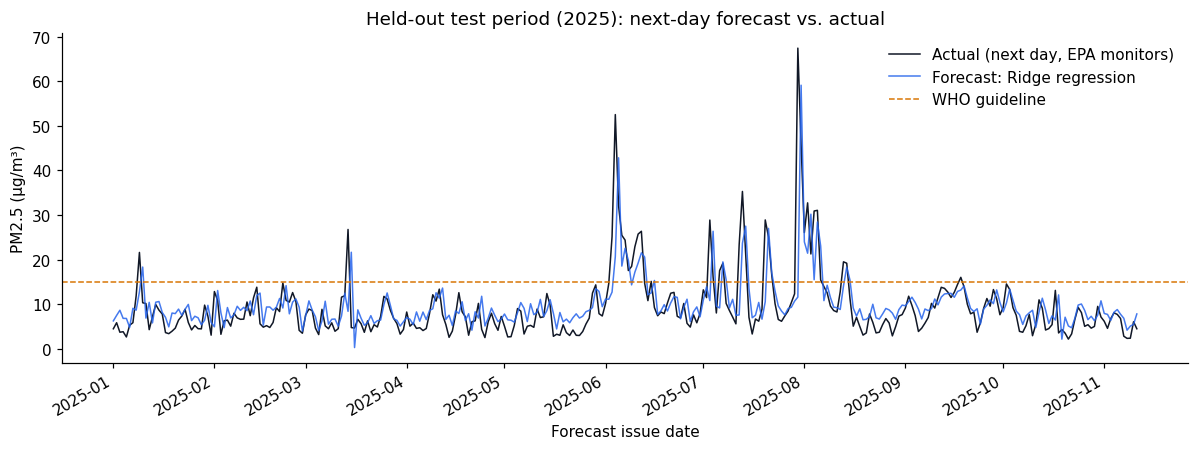

In [8]:
best = preds[best_name]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(y_test.index, y_test, lw=1, color="#111827", label="Actual (next day, EPA monitors)")
ax.plot(best.index, best, lw=1, color="#2563eb", alpha=0.85, label=f"Forecast: {best_name}")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1, label="WHO guideline")
ax.set_xlabel("Forecast issue date")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Held-out test period (2025): next-day forecast vs. actual")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/03_test_forecast.png", bbox_inches="tight")
plt.show()

## 6. Where the model fails

In [9]:
errors = (best - y_test).rename("error")
worst = errors.abs().nlargest(8).index
fail = pd.DataFrame({"actual": y_test[worst].round(1), "forecast": best[worst].round(1),
                     "error": errors[worst].round(1)}).sort_values("error")
fail

,actual,forecast,error
date,,,
2025-07-30,67.4,11.6,-55.8
2025-06-04,52.5,20.7,-31.8
2025-03-14,26.8,8.4,-18.3
2025-07-20,28.9,10.6,-18.3
2025-07-03,28.9,10.8,-18.0
2025-07-12,23.4,7.6,-15.8
2025-08-04,30.9,15.5,-15.4
2025-03-15,4.8,21.7,16.9


Seven of the eight worst misses are **underestimates on days when air quality
suddenly deteriorated**, and the eighth is the mirror image, an overestimate
the day after a spike. That makes physical sense: wildfire smoke arrives from
hundreds of kilometers away, and nothing in *Chicago's own* measurements today
can see it coming (or see it leaving). So instead of stopping at "that's our
limitation," we tried to fix it.

## 7. Attacking the failure: smoke signals from upwind

Canadian wildfire smoke reaches Chicago from the north and northwest. Air that
will be over Chicago tomorrow is over **Minneapolis, Green Bay, Madison and
Thunder Bay today**. We add 10 features, all legitimately available at forecast
time: the CAMS estimate for Chicago today (an independent, physics-based
nowcast), each upwind city's CAMS PM2.5 today and its one-day change, and the
maximum across the four cities.
We designed these features after reviewing the local model's 2025 misses,
so the enhanced model's 2025 results are exploratory.

In [10]:
UPWIND_CITIES = ["minneapolis", "green_bay", "madison", "thunder_bay"]

def add_smoke_signals(f, cams_series, upwind):
    f = f.copy()
    f["cams_today"] = cams_series
    for c in UPWIND_CITIES:
        f[f"up_{c}"] = upwind[c]
        f[f"up_{c}_chg"] = upwind[c] - upwind[c].shift(1)
    f["up_max"] = upwind[UPWIND_CITIES].max(axis=1)
    return f

data_sm = add_smoke_signals(features, cams, up).join(target).dropna()
tr_sm, te_sm = before_cutoff(data_sm, SPLIT), data_sm[data_sm.index >= SPLIT]
model_sm = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(
    tr_sm.drop(columns="pm25_tomorrow"), tr_sm["pm25_tomorrow"])
pred_sm = pd.Series(model_sm.predict(te_sm.drop(columns="pm25_tomorrow")), index=te_sm.index)

# "Onset days": test days where air quality suddenly deteriorated
# (tomorrow's actual PM2.5 at least 10 ug/m3 worse than today's)
onset = y_test.index[(y_test - X_test["epa_today"]) > 10]
compare = pd.DataFrame({
    "Persistence": X_test["epa_today"], "Local only": best, "Local + smoke signals": pred_sm})
smoke_results = pd.DataFrame({
    name: {"Test MAE (µg/m³)": mean_absolute_error(y_test, p),
           f"MAE on {len(onset)} sudden-onset days": mean_absolute_error(y_test[onset], p[onset])}
    for name, p in compare.items()
}).T.round(2)
smoke_results

,Test MAE (µg/m³),MAE on 8 sudden-onset days
Persistence,3.46,21.84
Local only,3.23,22.76
Local + smoke signals,3.11,17.86


## 8. The hardest test there is: June 2023, replayed

On June 27, 2023, Chicago's monitors measured 134 µg/m³, among the worst air in
the world that day. We retrain using **only data available before June 2023**
and replay the crisis day by day. (This is also an independent check on the
smoke-signal idea, which we designed after studying 2025 failures.)

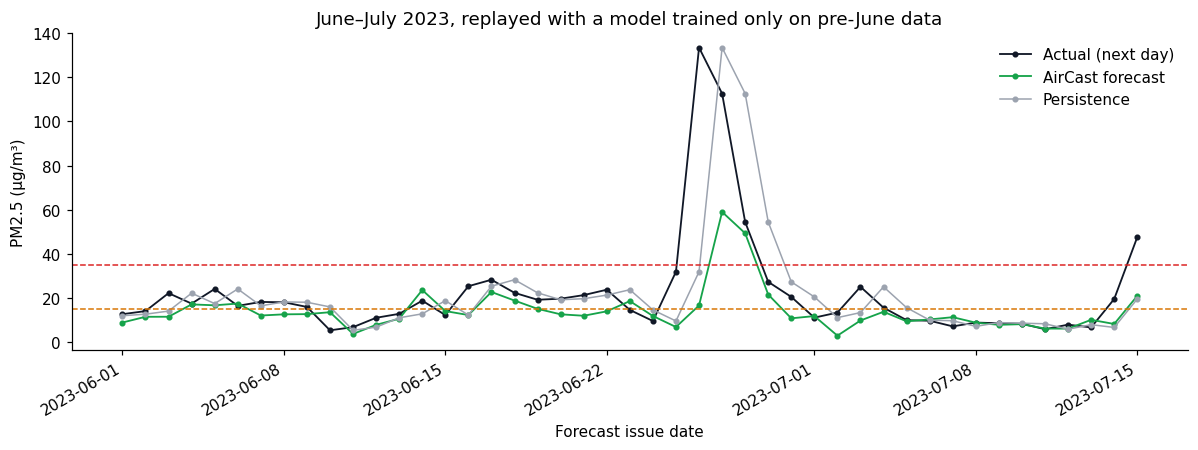

,actual_tomorrow,aircast,persistence,aircast_warns,persistence_warns
date,,,,,
2023-06-23,14.5,18.5,23.6,True,True
2023-06-24,9.4,11.7,14.5,False,False
2023-06-25,31.8,6.7,9.4,False,False
2023-06-26,133.5,16.5,31.8,True,True
2023-06-27,112.6,58.9,133.5,True,True
2023-06-28,54.4,49.2,112.6,True,True
2023-06-29,27.2,21.4,54.4,True,True
2023-06-30,20.4,10.7,27.2,False,True


In [11]:
cs_tr = before_cutoff(data_sm, "2023-06-01")
cs_te = data_sm[("2023-06-01" <= data_sm.index) & (data_sm.index <= "2023-07-15")]
cs_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(
    cs_tr.drop(columns="pm25_tomorrow"), cs_tr["pm25_tomorrow"])
cs_pred = pd.Series(cs_model.predict(cs_te.drop(columns="pm25_tomorrow")), index=cs_te.index)
cs_actual, cs_persist = cs_te["pm25_tomorrow"], cs_te["epa_today"]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(cs_actual.index, cs_actual, "o-", ms=3, lw=1.2, color="#111827", label="Actual (next day)")
ax.plot(cs_pred.index, cs_pred, "o-", ms=3, lw=1.2, color="#16a34a", label="AirCast forecast")
ax.plot(cs_persist.index, cs_persist, "o-", ms=3, lw=1, color="#9ca3af", label="Persistence")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1)
ax.axhline(EPA_DAILY, color="#dc2626", ls="--", lw=1)
ax.set_xlabel("Forecast issue date")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("June–July 2023, replayed with a model trained only on pre-June data")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/04_case_study.png", bbox_inches="tight")
plt.show()

event = pd.DataFrame({"actual_tomorrow": cs_actual.round(1), "aircast": cs_pred.round(1),
                      "persistence": cs_persist.round(1)}).loc["2023-06-23":"2023-06-30"]
event["aircast_warns"] = cs_pred > WHO_DAILY
event["persistence_warns"] = cs_persist > WHO_DAILY
event

Both models missed the June 26 jump from 9 to 32 µg/m³. On June 26, both
warn for the following day. AirCast predicts 17 for the day that hit **134**.
The warning is correct, but the forecast badly understates the peak. Persistence is no better a
guide during the chaos. Our conclusion, which we'd tell our athletics director
to their face: AirCast's forecasts are useful on ordinary and moderately bad
days (most of the year), but **extreme smoke events need satellite plume data
that none of our inputs contain**. During such events, follow live official
advisories, not any day-ahead forecast.

## 9. How sure is each forecast? Prediction intervals

We estimate an 80% prediction interval from the 10th and 90th percentiles
of 2024 validation residuals. We fit the validation model on targets before
2024, then apply the offsets to 2025 forecasts from the model refit through
2024. We report observed coverage because refitting and changes in pollution
patterns can affect how well the offsets transfer.

In [12]:
val_split = "2024-01-01"
v_train = before_cutoff(data_sm, val_split)
v_val = tr_sm[tr_sm.index >= val_split]
val_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(
    v_train.drop(columns="pm25_tomorrow"), v_train["pm25_tomorrow"])
v_pred = pd.Series(val_model.predict(v_val.drop(columns="pm25_tomorrow")), index=v_val.index)
val_resid = v_val["pm25_tomorrow"] - v_pred
lo_q, hi_q = val_resid.quantile(0.10), val_resid.quantile(0.90)
covered = ((y_test >= pred_sm + lo_q) & (y_test <= pred_sm + hi_q)).mean()
print(f"80% interval from 2024 residuals: forecast {lo_q:+.1f} to {hi_q:+.1f} µg/m³")
print(f"Coverage on 2025 test year: {covered:.0%} (target: 80%)")

80% interval from 2024 residuals: forecast -4.8 to +3.5 µg/m³
Coverage on 2025 test year: 77% (target: 80%)


## 10. From forecast to decision: the two-level alert

The athletics director doesn't need a number, they need a yes/no by the end of
the school day. Like real weather services, we use two levels:

- **WARNING** (act: move practice indoors): predicted PM2.5 above the WHO daily
  guideline (15 µg/m³).
- **WATCH** (be ready: have an indoor backup): fires when the **top of the 80%
  prediction interval** exceeds the guideline: "bad air is within the likely
  range." A missed bad day (a child with asthma outdoors in smoke) costs far
  more than a false watch, so the WATCH deliberately trades precision for
  recall, but by a principled amount, set by the measured uncertainty.

**A design that failed, reported honestly:** our first idea was to tune the
WATCH trigger for a fixed 85% recall on the 2024 validation year. On the real
monitor target that design collapses: 2024's bad days were so hard to predict
that hitting 85% recall required alerting on 234 of 366 days at 6% precision,
an alarm nobody would listen to. The interval-based WATCH replaced it.

In [13]:
from sklearn.metrics import precision_score, recall_score

def warning_scores(y_true, y_pred, trigger, threshold=WHO_DAILY):
    actual, warned = y_true > threshold, y_pred > trigger
    return {"Alerts issued": int(warned.sum()),
            "Bad days (actual)": int(actual.sum()),
            "Recall (bad days caught)": recall_score(actual, warned),
            "Precision (alerts correct)": precision_score(actual, warned)}

watch_trigger = WHO_DAILY - hi_q  # pred + hi_q > 15  <=>  pred > 15 - hi_q
print(f"WATCH trigger: forecast > {watch_trigger:.1f} µg/m³ "
      f"(guideline 15 minus interval top {hi_q:+.1f})")
alerts = pd.DataFrame({
    "AirCast WATCH (interval extends above 15)": warning_scores(y_test, pred_sm, watch_trigger),
    "AirCast WARNING (forecast > 15)": warning_scores(y_test, pred_sm, WHO_DAILY),
    "Persistence (alert if today was bad)": warning_scores(y_test, X_test["epa_today"], WHO_DAILY),
}).T
alerts.round(2)

WATCH trigger: forecast > 11.5 µg/m³ (guideline 15 minus interval top +3.5)


,Alerts issued,Bad days (actual),Recall (bad days caught),Precision (alerts correct)
AirCast WATCH (interval extends above 15),63.0,34.0,0.88,0.48
AirCast WARNING (forecast > 15),31.0,34.0,0.71,0.77
Persistence (alert if today was bad),34.0,34.0,0.68,0.68


The WARNING beats persistence on **both** recall and precision, and the WATCH
catches nearly nine bad days in ten a day ahead, with about one false watch
per correct watch. The triggers use the guideline and 2024 residuals.

## 11. How far ahead does the forecast stay useful?

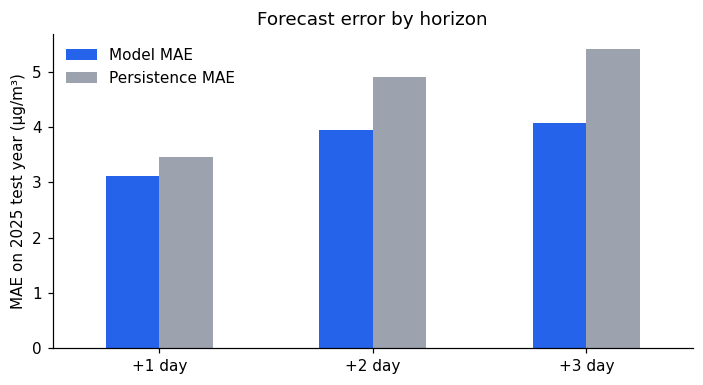

,Model MAE,Persistence MAE,Improvement
+1 day,3.11,3.46,10%
+2 day,3.95,4.91,20%
+3 day,4.08,5.41,25%


In [14]:
horizon_rows = {}
full_features = add_smoke_signals(features, cams, up)
for h in [1, 2, 3]:
    d_h = full_features.join(epa.shift(-h).rename("y")).dropna()
    tr, te = before_cutoff(d_h, SPLIT, h), d_h[d_h.index >= SPLIT]
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(tr.drop(columns="y"), tr["y"])
    horizon_rows[f"+{h} day"] = {
        "Model MAE": mean_absolute_error(te["y"], m.predict(te.drop(columns="y"))),
        "Persistence MAE": mean_absolute_error(te["y"], te["epa_today"]),
    }
horizons = pd.DataFrame(horizon_rows).T.round(2)
horizons["Improvement"] = (1 - horizons["Model MAE"] / horizons["Persistence MAE"]).map("{:.0%}".format)

ax = horizons[["Model MAE", "Persistence MAE"]].plot.bar(
    rot=0, color=["#2563eb", "#9ca3af"], figsize=(6.5, 3.6))
ax.set_ylabel("MAE on 2025 test year (µg/m³)")
ax.set_title("Forecast error by horizon")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/05_horizons.png", bbox_inches="tight")
plt.show()
horizons

## 12. What drives tomorrow's air quality in Chicago?

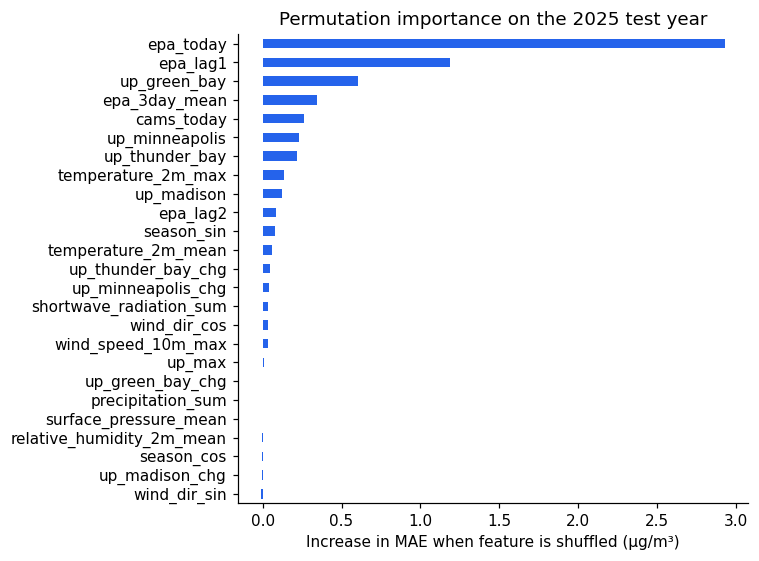

In [15]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(model_sm, te_sm.drop(columns="pm25_tomorrow"),
                             te_sm["pm25_tomorrow"], n_repeats=10, random_state=0,
                             scoring="neg_mean_absolute_error")
imp_series = pd.Series(imp.importances_mean,
                       index=te_sm.drop(columns="pm25_tomorrow").columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5.2))
imp_series.plot.barh(ax=ax, color="#2563eb")
ax.set_xlabel("Increase in MAE when feature is shuffled (µg/m³)")
ax.set_title("Permutation importance on the 2025 test year")
fig.tight_layout(); fig.savefig("figures/06_importance.png", bbox_inches="tight")
plt.show()

## 13. Does it generalize? Chicago's model, tested on Milwaukee

We take the final model, trained **only on Chicago**, and apply it, with no
retraining, to Milwaukee's EPA monitors (150 km north, never seen in training).
Then we retrain the identical pipeline on Milwaukee's own data.

In [16]:
mke_wx = pd.read_csv("data/milwaukee.csv", parse_dates=["date"], index_col="date")
mke_epa = pd.read_csv("data/epa_milwaukee.csv", parse_dates=["date"],
                      index_col="date")["epa_pm25"].loc["2022-08-04":"2025-11-12"]
mke_data = add_smoke_signals(build_features(mke_epa, mke_wx), mke_wx["pm25"], up).join(
    mke_epa.shift(-1).rename("pm25_tomorrow")).dropna()
mke_train = before_cutoff(mke_data, SPLIT)
mke_test = mke_data[mke_data.index >= SPLIT]
mke_y = mke_test["pm25_tomorrow"]
mke_X = mke_test.drop(columns="pm25_tomorrow")

mke_asis = pd.Series(model_sm.predict(mke_X), index=mke_X.index)
mke_retrained = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(
    mke_train.drop(columns="pm25_tomorrow"), mke_train["pm25_tomorrow"])
mke_rt = pd.Series(mke_retrained.predict(mke_X), index=mke_X.index)
transfer = pd.DataFrame({
    "Chicago-trained model, applied as-is": {
        "MAE on Milwaukee 2025 (µg/m³)": mean_absolute_error(mke_y, mke_asis)},
    "Same pipeline, retrained on Milwaukee": {
        "MAE on Milwaukee 2025 (µg/m³)": mean_absolute_error(mke_y, mke_rt)},
    "Milwaukee persistence baseline": {
        "MAE on Milwaukee 2025 (µg/m³)": mean_absolute_error(mke_y, mke_test["epa_today"])},
}).T.round(2)
transfer

,MAE on Milwaukee 2025 (µg/m³)
"Chicago-trained model, applied as-is",3.65
"Same pipeline, retrained on Milwaukee",3.51
Milwaukee persistence baseline,3.60


An honest, useful split result: Chicago's trained weights do **not** beat
Milwaukee's own persistence baseline (each city's pollution has local
character) but the identical pipeline **retrained on Milwaukee's data does**.
The method generalizes; the weights are local, which is how a multi-city
deployment should work anyway.

## 14. Live demo: a real input producing a real result

`src/predict_tomorrow.py` fetches *current* conditions (Chicago + upwind cities)
and forecasts tomorrow. It uses the no-API-key CAMS pipeline so that anyone can
run it; a school district deploying the monitor-target model would plug in EPA's
free AirNow feed for the live monitor value. Run the command below in a
notebook cell with an internet connection.

In [17]:
# Optional live forecast: %run src/predict_tomorrow.py

## 15. Conclusions, honestly

In [18]:
p_mae = results.loc["Persistence (tomorrow = today)", "MAE (µg/m³)"]
m_mae = smoke_results.loc["Local + smoke signals", "Test MAE (µg/m³)"]
watch, warn = alerts.iloc[0], alerts.iloc[1]
print(f"Target: what EPA monitors will actually measure tomorrow")
print(f"Next-day MAE on 2025 test year: {m_mae} µg/m³ vs persistence {p_mae} "
      f"({1 - m_mae / p_mae:.0%} better)")
print(f"WATCH:   caught {watch['Recall (bad days caught)']:.0%} of bad days "
      f"({watch['Precision (alerts correct)']:.0%} of watches correct)")
print(f"WARNING: caught {warn['Recall (bad days caught)']:.0%} of bad days "
      f"({warn['Precision (alerts correct)']:.0%} of warnings correct)")

Target: what EPA monitors will actually measure tomorrow
Next-day MAE on 2025 test year: 3.11 µg/m³ vs persistence 3.46 (10% better)
WATCH:   caught 88% of bad days (48% of watches correct)


**What works:** the model beats persistence overall and at every horizon, the
smoke signals measurably cut sudden-onset error, the WARNING level beats
persistence on both recall and precision while the WATCH level catches almost
nine bad days in ten, and the pipeline retrains successfully on a second city.

**Where it fails, and why. We'd say this to the judges' faces:**
- **Extreme smoke events are not forecastable with our inputs.** June 27, 2023
  hit 134 µg/m³; our best model said 17. Even the CAMS atmospheric model only
  "saw" 50 that day. Detection needs satellite plume data (NOAA HMS); during
  such events people should follow live advisories, not day-ahead forecasts.
  Our tool's honest role is the ordinary 1-day-in-9 bad day, not the
  once-a-year catastrophe.
- **Interval coverage degrades under shift:** calibrated in calmer 2024, the
  intervals covered fewer than 80% of observed values in the 2025 test period.
  A deployment would recalibrate on a rolling window.
- **Weights are local:** Chicago's trained model does not beat Milwaukee's own
  persistence; the retrained pipeline does. Method transfers, weights don't.

**Limitations:** EPA "daily summary" files publish with delay, so the live
no-key demo runs on CAMS inputs; a real deployment would use EPA's free AirNow
live feed. This is a student prototype, not an official air-quality advisory.